# F25: Endelig volum-metoden i 2D

Denne notatboken hører til **F25** og kompendiets §3.6 (eksempelet «Varmeledning i en plate»). Den bygger på **F23** og **F24** (EVM i 1D) og på **F21** / øving 6 (2D med endelige differanser).

Vi løser den stasjonære varmeledningsligningen i 2D,
$$
\frac{\partial}{\partial x}\left(k\frac{\partial T}{\partial x}\right) + \frac{\partial}{\partial y}\left(k\frac{\partial T}{\partial y}\right) + q = 0 .
$$
Hvert kontrollvolum har nå **fire naboer** $W, E, S, N$ og **fire flater** $w, e, s, n$. En plate med tykkelse $t$ gir flatearealene $A_w = A_e = \delta y\,t$ og $A_s = A_n = \delta x\,t$. Den diskrete ligningen er den samme som i 1D, bare med to naboer til:
$$
a_P T_P = a_W T_W + a_E T_E + a_S T_S + a_N T_N + S^u, \qquad a_P = a_W + a_E + a_S + a_N - S_P,
$$
med $a_W = kA_w/\delta x$, $a_E = kA_e/\delta x$, $a_S = kA_s/\delta y$ og $a_N = kA_n/\delta y$.

In [1]:
import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt

## 1. Gitteret og nummereringen av cellene

Vi setter opp punktene i hver retning **akkurat som i F23**: randpunktene først og sist, og nodene midt i hvert kontrollvolum. Med `m` kontrollvolum i $x$-retning og `n` i $y$-retning er det `m*n` ukjente.

Cellene nummereres **rad for rad**, som i øving 6: celle `(i, j)` (kolonne `i`, rad `j`, begge fra 0) får nummeret `p = j*m + i`. (I kompendiet teller vi fra 1, så celle 1 der er celle 0 her.) Da er naboene
$$
W = p-1, \qquad E = p+1, \qquad S = p-m, \qquad N = p+m ,
$$
og løsningsvektoren `u` kan gjøres om til et rutenett med `U = np.reshape(u, (n, m))`, der `U[j, i]` er temperaturen i celle `(i, j)`.

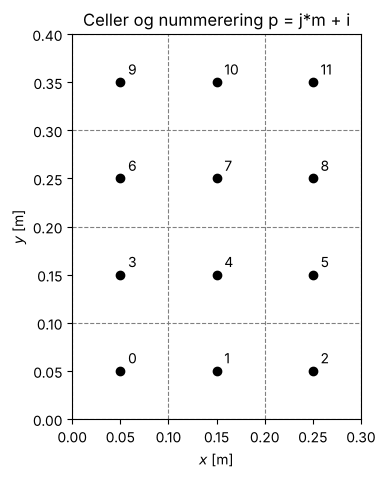

In [2]:
Lx, Ly = 0.3, 0.4        # bredde og høyde [m]
m, n = 3, 4              # antall kontrollvolum i x- og y-retning

deltax = Lx / m
x = np.zeros(m + 2)
x[1:-1] = deltax / 2 + deltax * np.arange(m)
x[-1] = Lx

deltay = Ly / n
y = np.zeros(n + 2)
y[1:-1] = deltay / 2 + deltay * np.arange(n)
y[-1] = Ly

plt.figure(figsize=(4, 5))
for xv in np.arange(m + 1) * deltax: plt.axvline(xv, color="gray", lw=0.8, ls="--")
for yv in np.arange(n + 1) * deltay: plt.axhline(yv, color="gray", lw=0.8, ls="--")
X, Y = np.meshgrid(x[1:-1], y[1:-1])
plt.plot(X, Y, "ko")
for j in range(n):
    for i in range(m):
        plt.text(x[i + 1] + 0.008, y[j + 1] + 0.008, str(j * m + i))
plt.xlim(0, Lx); plt.ylim(0, Ly); plt.gca().set_aspect("equal")
plt.xlabel("$x$ [m]"); plt.ylabel("$y$ [m]"); plt.title("Celler og nummerering p = j*m + i")
plt.show()

## 2. Koeffisientene, celle for celle

Vi bygger `L` og `F` ved å gå gjennom cellene én for én, nøyaktig slik vi gjør det for hånd i kompendiet. For hver av de fire sidene sjekker vi om det ligger en nabocelle der:

* **Nabocelle:** koblingen $a = kA/\delta$ legges til diagonalen, og $-a$ settes inn i kolonnen til naboen.
* **Vegg med kjent temperatur** $T_B$: koblingen kuttes, og avstanden til veggen er $\delta/2$. Det gir $S_P \to S_P - 2kA/\delta$ og $S^u \to S^u + (2kA/\delta)\,T_B$, som i F23.
* **Vegg med kjent fluks** $q_B$ (varme *inn*, W/m$^2$): koblingen kuttes, og $S^u \to S^u + q_B A$, som i F24. En isolert vegg er $q_B = 0$.

Til slutt er diagonalen $a_P = a_W + a_E + a_S + a_N - S_P$, og `F` inneholder $S^u$. En eventuell konstant varmekilde $q$ (W/m$^3$) gir $S^u = q\,\delta x\,\delta y\,t$ i hver celle.

In [3]:
def evm_2d(Lx, Ly, m, n, k, t, rand, q=0.0):
    """Endelig volum-metode for  div(k grad T) + q = 0  på [0, Lx] x [0, Ly], plate med tykkelse t.

    rand: dict med nøklene "V", "H", "S", "N" (vest, øst, sør, nord). Hver verdi er enten
          ("T", T_B)     -- kjent temperatur (tall eller funksjon av posisjonen langs veggen), eller
          ("fluks", q_B) -- kjent varmefluks INN i platen [W/m^2]; isolert vegg: q_B = 0.
    Returnerer x, y (med randpunktene) og L, F slik at L u = F."""
    # Rutenettgenerering
    deltax = Lx / m
    x = np.zeros(m + 2); x[1:-1] = deltax / 2 + deltax * np.arange(m); x[-1] = Lx
    deltay = Ly / n
    y = np.zeros(n + 2); y[1:-1] = deltay / 2 + deltay * np.arange(n); y[-1] = Ly

    Ax = deltay * t      # areal av vest- og østflaten
    Ay = deltax * t      # areal av sør- og nordflaten

    L = np.zeros((m * n, m * n))
    F = np.zeros(m * n)
    for j in range(n):
        for i in range(m):
            p = j * m + i
            Su = q * deltax * deltay * t   # kildeleddet
            SP = 0.0
            # (side, finnes nabocelle?, naboens nummer, flateareal, avstand, posisjon langs veggen)
            sider = [("V", i > 0,     p - 1, Ax, deltax, y[j + 1]),
                     ("H", i < m - 1, p + 1, Ax, deltax, y[j + 1]),
                     ("S", j > 0,     p - m, Ay, deltay, x[i + 1]),
                     ("N", j < n - 1, p + m, Ay, deltay, x[i + 1])]
            for side, nabo, pn, A, d, s in sider:
                if nabo:
                    a = k * A / d
                    L[p, pn] = -a          # -a_W, -a_E, -a_S eller -a_N
                    L[p, p] += a
                else:
                    typ, verdi = rand[side]
                    if typ == "T":
                        TB = verdi(s) if callable(verdi) else verdi
                        SP -= 2 * k * A / d
                        Su += 2 * k * A / d * TB
                    elif typ == "fluks":
                        Su += verdi * A
            L[p, p] -= SP                  # a_P = a_W + a_E + a_S + a_N - S_P
            F[p] = Su
    return x, y, L, F

## 3. Eksempelet fra kompendiet: plate med varmefluks inn fra vest

En plate med tykkelse $t = 1$ cm, bredde $0.3$ m og høyde $0.4$ m har $k = 1000$ W/(m K).

* **Vest:** kjent varmefluks inn, $q_V = 500$ kW/m$^2$.
* **Sør og øst:** isolert.
* **Nord:** kjent temperatur $T_N = 100\,^\circ$C.

Med $3\times 4$ kontrollvolum er $\delta x = \delta y = 0.1$ m, og alle indre koblinger er $kA/\delta x = 1000\cdot 0.1\cdot 0.01/0.1 = 10$. Vi skriver ut diagonalen ($a_P$), høyresiden ($S^u$) og løsningen ordnet slik cellene ligger i platen (nord øverst), og sammenligner med tabellene i kompendiet.

In [4]:
k, t = 1000.0, 0.01
rand = {"V": ("fluks", 500e3),
        "H": ("fluks", 0.0),     # isolert
        "S": ("fluks", 0.0),     # isolert
        "N": ("T", 100.0)}

x, y, L, F = evm_2d(Lx, Ly, m, n, k, t, rand)
u = la.solve(L, F)
U = np.reshape(u, (n, m))        # U[j, i]: rad j (y-retning), kolonne i (x-retning)

np.set_printoptions(precision=1, suppress=True)
print("a_P (nord øverst):\n", np.diag(L).reshape(n, m)[::-1])
print("\nS^u (nord øverst):\n", F.reshape(n, m)[::-1])
print("\nTemperatur (nord øverst):\n", U[::-1])

a_P (nord øverst):
 [[40. 50. 40.]
 [30. 40. 30.]
 [30. 40. 30.]
 [20. 30. 20.]]

S^u (nord øverst):
 [[2500. 2000. 2000.]
 [ 500.    0.    0.]
 [ 500.    0.    0.]
 [ 500.    0.    0.]]

Temperatur (nord øverst):
 [[146.3 129.7 124. ]
 [205.6 178.2 166.2]
 [242.3 211.2 196.5]
 [260.  227.8 212.2]]


Koeffisientene og temperaturene er de samme som i kompendiet. Legg merke til at `[::-1]` bare snur radene for utskriften, slik at nord kommer øverst.

### Energibalansen

Gjennom vestveggen strømmer det inn $q_V A_w$ per celle. Ut gjennom nordveggen går fluksen fra nodene til veggen over avstanden $\delta y/2$, altså $\frac{2kA_n}{\delta y}(T_P - T_N)$ per celle i den øverste raden. Siden metoden er konservativ, skal de to være like -- på ethvert gitter.

In [5]:
def energibalanse(U, m, n, k, t, qV, TN):
    deltax, deltay = Lx / m, Ly / n      # bruker platen fra over: Lx = 0.3, Ly = 0.4
    inn = qV * deltay * t * n                                     # gjennom vestveggen
    ut = np.sum(2 * k * deltax * t / deltay * (U[-1, :] - TN))    # gjennom nordveggen (øverste rad)
    return inn, ut

inn, ut = energibalanse(U, m, n, k, t, 500e3, 100.0)
print(f"Inn gjennom vest: {inn:.4f} W,  ut gjennom nord: {ut:.4f} W")

Inn gjennom vest: 2000.0000 W,  ut gjennom nord: 2000.0000 W


## 4. Et finere gitter -- og et varmekart

Det grove gitteret gir riktig energibalanse, men temperaturfordelingen er grov. Vi gjentar med flere kontrollvolum. Vi tegner med `origin="lower"`, slik at rad `j = 0` (sør) kommer nederst. (I øving 6 ble `imshow` brukt uten dette, og da ble $y$-aksen speilvendt.)

30x40: inn 2000.0000 W, ut 2000.0000 W, høyeste temperatur 279.9 C


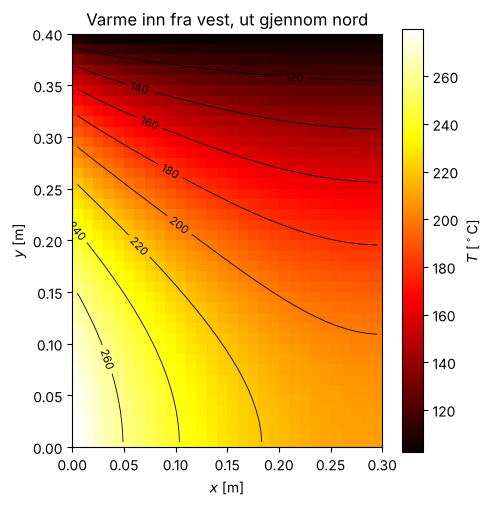

In [6]:
m2, n2 = 30, 40
x2, y2, L2, F2 = evm_2d(Lx, Ly, m2, n2, k, t, rand)
U2 = np.reshape(la.solve(L2, F2), (n2, m2))

inn, ut = energibalanse(U2, m2, n2, k, t, 500e3, 100.0)
print(f"{m2}x{n2}: inn {inn:.4f} W, ut {ut:.4f} W, høyeste temperatur {U2.max():.1f} C")

plt.figure(figsize=(5, 5.5))
plt.imshow(U2, origin="lower", extent=[0, Lx, 0, Ly], cmap="hot")
plt.colorbar(label=r"$T$ [$^\circ$C]")
cs = plt.contour(x2[1:-1], y2[1:-1], U2, levels=8, colors="k", linewidths=0.6)
plt.clabel(cs, fmt="%.0f", fontsize=8)
plt.xlabel("$x$ [m]"); plt.ylabel("$y$ [m]")
plt.title("Varme inn fra vest, ut gjennom nord")
plt.show()

Isotermene står **vinkelrett** på de isolerte veggene (sør og øst): der er $\partial T/\partial n = 0$. Det er varmest i det sørvestlige hjørnet.

Hvordan endrer den høyeste temperaturen seg når gitteret forfines?

In [7]:
for faktor in [1, 2, 4, 8, 16]:
    mm, nn = 3 * faktor, 4 * faktor
    _, _, Lf, Ff = evm_2d(Lx, Ly, mm, nn, k, t, rand)
    Uf = np.reshape(la.solve(Lf, Ff), (nn, mm))
    inn, ut = energibalanse(Uf, mm, nn, k, t, 500e3, 100.0)
    print(f"{mm:3d} x {nn:3d}:  høyeste T = {Uf.max():6.1f} C,   inn - ut = {inn - ut: .1e} W")

  3 x   4:  høyeste T =  260.0 C,   inn - ut =  6.8e-13 W
  6 x   8:  høyeste T =  270.6 C,   inn - ut =  6.8e-13 W
 12 x  16:  høyeste T =  276.3 C,   inn - ut =  5.5e-12 W


 24 x  32:  høyeste T =  279.3 C,   inn - ut = -9.5e-12 W


 48 x  64:  høyeste T =  280.9 C,   inn - ut = -1.8e-11 W


Den høyeste temperaturen øker fra $260\,^\circ$C (med $3\times 4$) mot omtrent $281\,^\circ$C. (Høyeste *nodeverdi* ligger i en celle, og cellene kommer nærmere hjørnet når gitteret forfines.) Energibalansen er eksakt hele veien.

## 5. Sjekk mot en eksakt løsning

For å se hvor nøyaktig metoden er, løser vi Laplace-ligningen på enhetskvadratet med $T = \sin(\pi x)$ på nordveggen og $T = 0$ på de andre veggene. Den eksakte løsningen er
$$
T(x,y) = \sin(\pi x)\,\frac{\sinh(\pi y)}{\sinh(\pi)} .
$$
Her er $k = 1$ og $t = 1$. Med `("T", funksjon)` kan randtemperaturen variere langs veggen.

In [8]:
rand_L = {"V": ("T", 0.0), "H": ("T", 0.0), "S": ("T", 0.0),
          "N": ("T", lambda s: np.sin(np.pi * s))}

feil = []
mer = [5, 10, 20, 40]
for mm in mer:
    xe, ye, Le, Fe = evm_2d(1.0, 1.0, mm, mm, 1.0, 1.0, rand_L)
    Ue = np.reshape(la.solve(Le, Fe), (mm, mm))
    X, Y = np.meshgrid(xe[1:-1], ye[1:-1])
    eksakt = np.sin(np.pi * X) * np.sinh(np.pi * Y) / np.sinh(np.pi)
    feil.append(np.max(np.abs(Ue - eksakt)))
    print(f"m = n = {mm:3d}:  maks feil = {feil[-1]:.2e}")

for i in range(1, len(mer)):
    print(f"h halveres fra 1/{mer[i-1]} til 1/{mer[i]}:  feilen deles på {feil[i-1] / feil[i]:.2f}")

m = n =   5:  maks feil = 2.58e-02
m = n =  10:  maks feil = 9.10e-03
m = n =  20:  maks feil = 2.68e-03
m = n =  40:  maks feil = 7.20e-04
h halveres fra 1/5 til 1/10:  feilen deles på 2.84
h halveres fra 1/10 til 1/20:  feilen deles på 3.40
h halveres fra 1/20 til 1/40:  feilen deles på 3.72


Når $h$ halveres, deles feilen på et tall som nærmer seg $4 = 2^2$: metoden er av **andre orden**, som i 1D.

## 6. Matrisen -- og sammenhengen med F21 og øving 6

Med nummereringen `p = j*m + i` får matrisen fem diagonaler: hoveddiagonalen, de to rett ved siden av (naboene $W$ og $E$), og to i avstand `m` (naboene $S$ og $N$). Det er samme struktur som fempunktsformelen i F21.

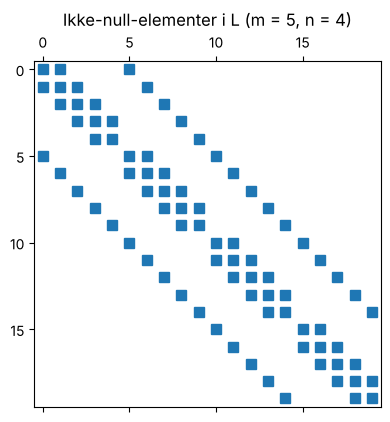

[[ 6. -1.  0.  0.  0. -1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [-1.  5. -1.  0.  0.  0. -1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0. -1.  5. -1.  0.  0.  0. -1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0. -1.  5. -1.  0.  0.  0. -1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0. -1.  6.  0.  0.  0.  0. -1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [-1.  0.  0.  0.  0.  5. -1.  0.  0.  0. -1.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0. -1.  0.  0.  0. -1.  4. -1.  0.  0.  0. -1.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0. -1.  0.  0.  0. -1.  4. -1.  0.  0.  0. -1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0. -1.  0.  0.  0. -1.  4. -1.  0.  0.  0. -1.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0. -1.  0.  0.  0. -1.  5.  0.  0.  0.  0. -1.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0. -1.  0.  0.  0.  0.  5. -1.  0.  0.  0. -1.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0. -1.  0.  0.  0. -1.  4. -1.  0.  0.  0. -1.  0.  0.  0.]
 [ 0

In [9]:
xs, ys, Ls, Fs = evm_2d(1.0, 0.8, 5, 4, 1.0, 1.0, rand_L)   # delta x = delta y = 0.2
plt.figure(figsize=(4.5, 4.5))
plt.spy(Ls, markersize=7)
plt.title("Ikke-null-elementer i L (m = 5, n = 4)")
plt.show()

np.set_printoptions(precision=1, suppress=True, linewidth=150)
print(Ls)

For en indre celle med $\delta x = \delta y = h$ og $k = t = 1$ er alle koblingene $a = kA/h = h/h = 1$, og raden i `L` blir `[-1, ..., -1, 4, -1, ..., -1]`. Deler vi på $h^2$, er det **nøyaktig fempunktsformelen** fra F21 (med motsatt fortegn). Forskjellen ligger i randradene: der står det $1 + 1 + 1 + 2 = 5$ (eller $1 + 1 + 2 + 2 = 6$ i hjørnene), fordi avstanden til veggen bare er $h/2$ -- akkurat som tallet $3$ i stedet for $2$ i 1D.

Med fast temperatur på alle veggene er randradene $1 + 1 + 1 + 2 = 5$ og hjørneradene $1 + 1 + 2 + 2 = 6$.

## 7. Samme matrise med `np.kron` -- som i øving 6

Løkken over cellene er nær det vi gjør for hånd. Men på et **uniformt gitter** kan vi bygge den samme matrisen mye raskere med `np.kron`, akkurat som differansematrisen i øving 6. (Dette er øving 7a.)

**Idé:** Koblingene i $x$-retning er de samme i hver rad av celler, og koblingene i $y$-retning er de samme i hver kolonne. Vi trenger bare **1D-matrisen fra F23** i hver retning:

* `Lm` ($m\times m$): 1D-volummetoden i $x$-retning, med $1/\delta x$ mellom nodene og $1/(\delta x/2)$ mot veggene.
* `Ln` ($n\times n$): det samme i $y$-retning.

En vest/øst-flate har areal $\delta y\,t$, så $x$-koblingene skal ganges med $k\,\delta y\,t$. En sør/nord-flate har areal $\delta x\,t$, så $y$-koblingene skal ganges med $k\,\delta x\,t$. Med nummereringen `p = j*m + i` blir det
$$
L = k\,t\,\Big(\delta y\;\texttt{kron}(I_n, L_m) \;+\; \delta x\;\texttt{kron}(L_n, I_m)\Big).
$$
Første ledd kobler naboene $W$ og $E$ innenfor hver rad; andre ledd kobler $S$ og $N$ innenfor hver kolonne. På diagonalen får en indre celle $2+2 = 4$, en randcelle $3+2 = 5$ og en hjørnecelle $3+3 = 6$ (ganger $k\,t$, når $\delta x = \delta y$) -- nøyaktig som over.

Randleddene i `F` kommer fra de samme halve avstandene: mot vestveggen er bidraget $k\,\delta y\,t\cdot T_V/(\delta x/2)$ i den første cellen i hver rad, osv. Med enhetsvektorer `e_forst` og `e_sist` kan også de skrives med `np.kron`, som i øving 6.

In [10]:
def evm_1d_matrise(lengde, m):
    """1D-matrisen fra F23 (med k*A = 1) og kjent temperatur i begge ender."""
    delta = lengde / m
    x = np.zeros(m + 2)
    x[1:-1] = delta / 2 + delta * np.arange(m)
    x[-1] = lengde
    dx = x[1:] - x[:-1]
    koeff_diag  = 1 / dx[:-1] + 1 / dx[1:]
    koeff_over  = -1 / dx[1:-1]
    koeff_under = -1 / dx[1:-1]
    L1 = np.diag(koeff_over, 1) + np.diag(koeff_under, -1) + np.diag(koeff_diag, 0)
    return x, dx, L1

# Laplace-eksempelet fra avsnitt 5: enhetskvadratet, T = sin(pi x) på nordveggen, 0 ellers
k1, t1 = 1.0, 1.0
mk = nk = 20
xk, dxv, Lm = evm_1d_matrise(1.0, mk)
yk, dyv, Ln = evm_1d_matrise(1.0, nk)
dxk, dyk = 1.0 / mk, 1.0 / nk
Im, In = np.eye(mk), np.eye(nk)

L_kron = k1 * t1 * (dyk * np.kron(In, Lm) + dxk * np.kron(Ln, Im))

# Randverdier
T_S = np.zeros(mk);  T_N = np.sin(np.pi * xk[1:-1])     # langs x
T_V = np.zeros(nk);  T_H = np.zeros(nk)                  # langs y
e_forst_m = np.zeros(mk); e_forst_m[0] = 1;  e_sist_m = np.zeros(mk); e_sist_m[-1] = 1
e_forst_n = np.zeros(nk); e_forst_n[0] = 1;  e_sist_n = np.zeros(nk); e_sist_n[-1] = 1

F_kron = k1 * t1 * (dyk * (np.kron(T_V, e_forst_m) / dxv[0] + np.kron(T_H, e_sist_m) / dxv[-1])
                + dxk * (np.kron(e_forst_n, T_S) / dyv[0] + np.kron(e_sist_n, T_N) / dyv[-1]))

# Sammenlign med løkken i evm_2d
_, _, L_lokke, F_lokke = evm_2d(1.0, 1.0, mk, nk, k1, t1, rand_L)
print("Samme L:", np.allclose(L_kron, L_lokke))
print("Samme F:", np.allclose(F_kron, F_lokke))

U_kron = np.reshape(la.solve(L_kron, F_kron), (nk, mk))
Xk, Yk = np.meshgrid(xk[1:-1], yk[1:-1])
print("Maks feil mot eksakt løsning:", np.max(np.abs(U_kron - np.sin(np.pi * Xk) * np.sinh(np.pi * Yk) / np.sinh(np.pi))))

Samme L: True
Samme F: True
Maks feil mot eksakt løsning: 0.0026779815606616797


Begge måtene gir **nøyaktig samme ligningssystem**. Løkken er mest fleksibel (hver vegg kan ha sin egen type randbetingelse, og koeffisientene kan variere fra celle til celle), mens `np.kron` er kompakt og rask på uniforme gitre. Med en isolert vegg endres bare 1D-matrisen i den retningen: $1/(\delta/2)$-leddet mot den veggen faller bort, akkurat som i F24.

## Prøv selv

1. **Varmekilde i platen.** Legg til en jevn varmeproduksjon `q = 1e7` (W/m$^3$) i eksempelet i avsnitt 3 (argumentet `q` i `evm_2d`). Hvor mye varme må nå gå ut gjennom nordveggen? Utvid `energibalanse` og sjekk.
2. **Andre randbetingelser.** Gi østveggen kjent temperatur $T = 100\,^\circ$C i stedet for isolert. Hvordan endrer varmekartet seg, og hvordan fordeler varmen seg mellom nord- og østveggen?
3. **Gauss-Seidel over cellene.** Løs $3\times 4$-eksempelet med Gauss-Seidel i stedet for `la.solve`: gå gjennom cellene og sett $T_P = \big(a_WT_W + a_ET_E + a_ST_S + a_NT_N + S^u\big)/a_P$, med de nyeste verdiene. Hvor mange iterasjoner trengs for fire korrekte desimaler? (Hint: koeffisientene står i `L` og `F`.)